# Анализ системы метрик приложения

Вы — продуктовый аналитик приложения Procrastinate Pro+, которое предоставляет пользователям доступ к развлекательному контенту: видео, подкастам и блогам. Пользователи могут выбрать несколько пакетов контента. Пакеты различаются по цене, объёму и содержанию.

К началу лета в приложении появился новый вид контента — спортивный. С его помощью менеджеры стремятся расширить аудиторию, добавив в неё пользователей, которые увлекаются спортом и здоровым образом жизни.

К запуску нового контента была скорректирована маркетинговая стратегия привлечения пользователей. Согласно бизнес-модели продукта, привлечение должно окупиться за первые 28 дней (4 недели).

После запуска нового контента и изменения стратегии интерес к продукту в целом вырос, но выручка начала стагнировать. Нужно разобраться, почему это происходит.

Ваши задачи:
- провести анализ юнит-экономики продукта в динамике за первые 28 дней;
- разобраться в причинах стагнации выручки;
- определить, какие источники привлечения приносят прибыль, а какие не выходят на уровень окупаемости;
- дать рекомендации отделу маркетинга.


### Данные

В вашем распоряжении есть данные о посещениях приложения, покупках и расходах на маркетинг.
Данные собраны в трёх датасетах.

1. Датасет `ppro_visits.csv` — информация о посещениях приложения пользователями, которые зарегистрировались с 1 апреля 2024 года по 30 ноября 2024 года:
    - `user_id` — уникальный идентификатор пользователя;
    - `region` — страна пользователя;
    - `device` — категория устройства пользователя;
    - `channel` — идентификатор рекламного источника, из которого пришёл пользователь;
    - `session_start` — дата и время начала сессии;
    - `session_end` — дата и время окончания сессии.

2. Датасет `ppro_orders.csv` — информация о покупках:
    - `user_id` — уникальный идентификатор пользователя, который сделал покупку;
    - `event_dt` — дата и время покупки;
    - `revenue` — выручка.

3. Датасет `ppro_costs.csv` — информация о затратах на маркетинг:
    - `dt` — дата
    - `channel` — идентификатор рекламного источника;
    - `costs` — затраты на этот рекламный источник в этот день.
    
### План проекта
- Загрузить и предобработать данные.
- Подготовить данные для когортного анализа.
- Рассчитать и проанализировать метрики вовлечённости в продукт.
- Рассчитать и проанализировать финансовые метрики CAC, LTV и ROI за первые 28 дней с момента привлечения.
- Исследовать метрики в разрезе источника привлечения.
- Рассчитать период окупаемости маркетинговых вложений.
- Сформулировать выводы и рекомендации.


## Загрузка и предобработка данных

Загрузите данные и получите основную информацию о них. Проведите необходимую предобработку. Основную информацию о данных и предобработке зафиксируйте в кратком промежуточном выводе.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
visits = pd.read_csv('https://code.s3.yandex.net/datasets/ppro_visits.csv')
orders = pd.read_csv('https://code.s3.yandex.net/datasets/ppro_orders.csv')
costs = pd.read_csv('https://code.s3.yandex.net/datasets/ppro_costs.csv')

In [5]:
print("Первые 5 строк visits:")
display(visits.head())
print("\nИнформация о данных visits:")
visits.info()
print("\nПропуски visits:")
print(visits.isna().sum())
print("\nПолные дубликаты строк visits:")
print(visits.duplicated().sum())

print("\nПервые 5 строк orders:")
display(orders.head())
print("\nИнформация о данных orders:")
orders.info()
print("\nПропуски orders:")
print(orders.isna().sum())
print("\nПолные дубликаты строк orders:")
print(orders.duplicated().sum())

print("\nПервые 5 строк costs:")
display(costs.head())
print("\nИнформация о данных costs:")
costs.info()
print("\nПропуски costs:")
print(costs.isna().sum())
print("\nПолные дубликаты строк costs:")
print(costs.duplicated().sum())

Первые 5 строк visits:


,user_id,region,device,channel,session_start,session_end
0,631105188566,India,desktop,MediaTornado,2024-04-01 03:48:00,2024-04-01 04:19:00
1,892885906464,India,tv,RocketSuperAds,2024-04-01 00:47:00,2024-04-01 01:14:00
2,517003690029,India,mobile,MediaTornado,2024-04-01 17:31:00,2024-04-01 17:53:00
3,185156659289,India,mobile,MediaTornado,2024-04-01 14:36:00,2024-04-01 14:51:00
4,409503040345,India,mobile,RocketSuperAds,2024-04-01 08:25:00,2024-04-01 08:45:00



Информация о данных visits:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 161865 entries, 0 to 161864
Data columns (total 6 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   user_id        161865 non-null  int64 
 1   region         161865 non-null  object
 2   device         161865 non-null  object
 3   channel        161865 non-null  object
 4   session_start  161865 non-null  object
 5   session_end    161865 non-null  object
dtypes: int64(1), object(5)
memory usage: 7.4+ MB

Пропуски visits:
user_id          0
region           0
device           0
channel          0
session_start    0
session_end      0
dtype: int64

Полные дубликаты строк visits:
0

Первые 5 строк orders:


,user_id,event_dt,revenue
0,771951256319,2024-04-01 05:56:26,2.99
1,829942381059,2024-04-01 14:55:02,2.99
2,727879856738,2024-04-01 22:15:09,14.99
3,481270888930,2024-04-01 06:05:14,2.99
4,844695029762,2024-04-01 01:19:52,2.99



Информация о данных orders:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 33893 entries, 0 to 33892
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   user_id   33893 non-null  int64  
 1   event_dt  33893 non-null  object 
 2   revenue   33893 non-null  float64
dtypes: float64(1), int64(1), object(1)
memory usage: 794.5+ KB

Пропуски orders:
user_id     0
event_dt    0
revenue     0
dtype: int64

Полные дубликаты строк orders:
0

Первые 5 строк costs:


,dt,channel,costs
0,2024-04-01,FaceBoom,124.938874
1,2024-04-02,FaceBoom,88.147779
2,2024-04-03,FaceBoom,120.779457
3,2024-04-04,FaceBoom,98.981253
4,2024-04-05,FaceBoom,109.044760



Информация о данных costs:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 976 entries, 0 to 975
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   dt       976 non-null    object 
 1   channel  976 non-null    object 
 2   costs    976 non-null    float64
dtypes: float64(1), object(2)
memory usage: 23.0+ KB

Пропуски costs:
dt         0
channel    0
costs      0
dtype: int64

Полные дубликаты строк costs:
0


In [6]:
print("Статистика по revenue:")
print(orders['revenue'].describe())
print("Количество revenue <= 0:", (orders['revenue'] <= 0).sum())

print("\nСтатистика по costs:")
print(costs['costs'].describe())
print("Количество costs = 0:", (costs['costs'] == 0).sum())

print("\nСессий с start > end:", (visits['session_start'] > visits['session_end']).sum())
print("Минимальная дата старта:", visits['session_start'].min())
print("Максимальная дата старта:", visits['session_start'].max())

Статистика по revenue:
count    33893.000000
mean         3.439945
std          2.191299
min          2.990000
25%          2.990000
50%          2.990000
75%          2.990000
max         29.990000
Name: revenue, dtype: float64
Количество revenue <= 0: 0

Статистика по costs:
count    976.000000
mean      81.691910
std       70.237689
min        9.048984
25%       19.546203
50%       54.282076
75%      134.499067
max      316.923419
Name: costs, dtype: float64
Количество costs = 0: 0

Сессий с start > end: 0
Минимальная дата старта: 2024-04-01 00:07:00
Максимальная дата старта: 2024-11-30 23:59:00


In [7]:
visits['session_start'] = pd.to_datetime(visits['session_start'])
visits['session_end'] = pd.to_datetime(visits['session_end'])
print(visits.dtypes)

orders['event_dt'] = pd.to_datetime(orders['event_dt'])
print(orders.dtypes)

costs['dt'] = pd.to_datetime(costs['dt'])
print(costs.dtypes)

user_id                   int64
region                   object
device                   object
channel                  object
session_start    datetime64[ns]
session_end      datetime64[ns]
dtype: object
user_id              int64
event_dt    datetime64[ns]
revenue            float64
dtype: object
dt         datetime64[ns]
channel            object
costs             float64
dtype: object


### Промежуточный вывод
- Данные загружены успешно, пропуски и дубликаты отсутствуют.

- Даты преобразованы в формат datetime.

- Аномалий (отрицательная выручка, costs = 0, session_start > session_end) не обнаружено.

- Данные готовы к когортному анализу.

## Подготовка данных к когортному анализу

Подготовьте данные к когортному анализу с учётом того, что вы будете изучать окупаемость привлечения пользователей за первые 28 дней.

Для каждого пользователя найдите:
- дату первой сессии (дата привлечения пользователя, `first_dt`);
- канал привлечения (`first_channel`);
- стоимость привлечения пользователя (`cac`).

Результаты сохраните в новой таблице, например, `profiles`.

Добавьте к данным с событиями и покупками информацию о первом источнике привлечения и дату привлечения пользователя из созданной таблицы. После этого рассчитайте дневной лайфтайм для каждого события или покупки и добавьте в таблицу в виде целого числа. В дальнейшем при проведении когортного анализа используйте информацию о первом источнике привлечения пользователя.

In [8]:
first_dates = visits.groupby('user_id')['session_start'].min().reset_index()

profiles = first_dates.merge(
    visits[['user_id', 'session_start', 'channel']],
    on=['user_id', 'session_start'],
    how='inner'
)
profiles.columns = ['user_id', 'first_dt', 'first_channel']

print("\nПервые 5 строк profiles:")
display(profiles.head())

print("\nИнформация о данных profiles:")
profiles.info()

print("\nДубликаты profiles['user_id']:")
print(profiles['user_id'].duplicated().sum())


Первые 5 строк profiles:


,user_id,first_dt,first_channel
0,26034876,2024-05-29 10:24:00,FaceBoom
1,69890364,2024-06-28 05:48:00,RocketSuperAds
2,75610104,2024-06-09 06:48:00,FaceBoom
3,76692397,2024-10-21 01:51:00,FaceBoom
4,80224421,2024-06-21 11:47:00,FaceBoom



Информация о данных profiles:
<class 'pandas.core.frame.DataFrame'>
Int64Index: 74856 entries, 0 to 74855
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   user_id        74856 non-null  int64         
 1   first_dt       74856 non-null  datetime64[ns]
 2   first_channel  74856 non-null  object        
dtypes: datetime64[ns](1), int64(1), object(1)
memory usage: 2.3+ MB

Дубликаты profiles['user_id']:
0


In [9]:
profiles['first_date'] = profiles['first_dt'].dt.date

cac_by_day_channel = profiles.groupby(['first_date', 'first_channel'])['user_id'].nunique().reset_index()
cac_by_day_channel.columns = ['date', 'channel', 'new_users']

costs['cost_date'] = costs['dt'].dt.date

cac_by_day_channel = cac_by_day_channel.merge(
    costs,
    left_on=['date', 'channel'],
    right_on=['cost_date', 'channel'],
    how='inner'
)

cac_by_day_channel = cac_by_day_channel[['date', 'channel', 'new_users', 'costs']]
cac_by_day_channel.columns = ['date', 'channel', 'new_users', 'total_costs']
cac_by_day_channel['cac'] = cac_by_day_channel['total_costs'] / cac_by_day_channel['new_users']

print("\nПервые 5 строк cac_by_day_channel:")
display(cac_by_day_channel.head())

print("\nИнформация о данных cac_by_day_channel:")
cac_by_day_channel.info()


Первые 5 строк cac_by_day_channel:


,date,channel,new_users,total_costs,cac
0,2024-04-01,FaceBoom,133,124.938874,0.939390
1,2024-04-01,MediaTornado,80,19.932806,0.249160
2,2024-04-01,RocketSuperAds,70,62.050000,0.886429
3,2024-04-01,TipTop,73,54.200101,0.742467
4,2024-04-02,FaceBoom,94,88.147779,0.937742



Информация о данных cac_by_day_channel:
<class 'pandas.core.frame.DataFrame'>
Int64Index: 976 entries, 0 to 975
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   date         976 non-null    object 
 1   channel      976 non-null    object 
 2   new_users    976 non-null    int64  
 3   total_costs  976 non-null    float64
 4   cac          976 non-null    float64
dtypes: float64(2), int64(1), object(2)
memory usage: 45.8+ KB


In [10]:
profiles = profiles.merge(
    cac_by_day_channel[['date', 'channel', 'cac']],
    left_on=['first_date', 'first_channel'],
    right_on=['date', 'channel'],
    how='left'
)

profiles = profiles.drop(columns=['first_date', 'date', 'channel'])

print("\nПервые 5 строк profiles:")
display(profiles.head())

print("\nИнформация о данных profiles:")
profiles.info()


Первые 5 строк profiles:


,user_id,first_dt,first_channel,cac
0,26034876,2024-05-29 10:24:00,FaceBoom,0.953250
1,69890364,2024-06-28 05:48:00,RocketSuperAds,0.604917
2,75610104,2024-06-09 06:48:00,FaceBoom,1.196159
3,76692397,2024-10-21 01:51:00,FaceBoom,1.147967
4,80224421,2024-06-21 11:47:00,FaceBoom,1.208981



Информация о данных profiles:
<class 'pandas.core.frame.DataFrame'>
Int64Index: 74856 entries, 0 to 74855
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   user_id        74856 non-null  int64         
 1   first_dt       74856 non-null  datetime64[ns]
 2   first_channel  74856 non-null  object        
 3   cac            74856 non-null  float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 2.9+ MB


## Анализ месячной динамики основных метрик продукта

**Задача 1**. Начните анализ данных с изучения динамики активности пользователей и их вовлечённости в продукт. Рассчитайте по всем данным значения DAU, MAU и Stickiness и визуализируйте их. Активными считайте всех пользователей, которые взаимодействовали с приложением.

**Задача 2**. В разрезе каждого месяца привлечения новых пользователей рассчитайте:
- Среднюю стоимость привлечения пользователя (CAC).
- Значение LTV и ROI с учётом покупок, совершённых за 28 дней с момента привлечения.

Здесь и далее при расчёте LTV и ROI учитывайте всех привлечённых пользователей когорты.

Визуализируйте метрики и сформулируйте небольшой промежуточный вывод. Сделайте акцент на общей динамике изменения метрик с учётом появления нового контента в начале лета.

In [11]:
dau = visits.groupby(visits['session_start'].dt.date)['user_id'].nunique().reset_index()
dau.columns = ['date', 'dau']
dau['date'] = pd.to_datetime(dau['date'])
dau['month'] = dau['date'].dt.to_period('M').dt.to_timestamp()
print("\nПервые 5 строк dau:")
display(dau.head())

mau = visits.groupby(visits['session_start'].dt.to_period('M'))['user_id'].nunique().reset_index()
mau.columns = ['month', 'mau']
mau['month'] = mau['month'].dt.to_timestamp()
print("\nПервые 5 строк mau:")
display(mau.head())

avg_dau_by_month = dau.groupby('month')['dau'].mean().reset_index()
avg_dau_by_month.columns = ['month', 'avg_dau']

stickiness = avg_dau_by_month.merge(
    mau, 
    on='month', 
    how='inner'
)
stickiness['stickiness'] = stickiness['avg_dau'] / stickiness['mau']

print("\nПервые 5 строк stickiness:")
display(stickiness.head())


Первые 5 строк dau:


,date,dau,month
0,2024-04-01,356,2024-04-01
1,2024-04-02,410,2024-04-01
2,2024-04-03,481,2024-04-01
3,2024-04-04,472,2024-04-01
4,2024-04-05,533,2024-04-01



Первые 5 строк mau:


,month,mau
0,2024-04-01,9069
1,2024-05-01,10849
2,2024-06-01,10240
3,2024-07-01,10864
4,2024-08-01,11977



Первые 5 строк stickiness:


,month,avg_dau,mau,stickiness
0,2024-04-01,488.333333,9069,0.053846
1,2024-05-01,576.967742,10849,0.053182
2,2024-06-01,580.366667,10240,0.056676
3,2024-07-01,615.000000,10864,0.056609
4,2024-08-01,681.193548,11977,0.056875


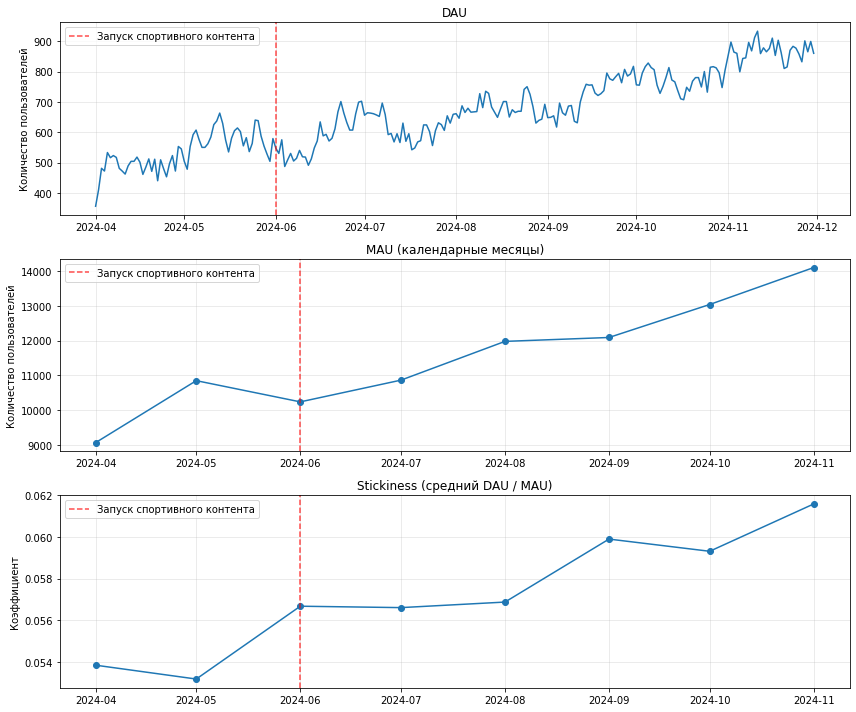

In [12]:
fig, axes = plt.subplots(3, 1, figsize=(12, 10))

axes[0].plot(dau['date'], dau['dau'])
axes[0].axvline(x=pd.Timestamp('2024-06-01'), color='red', linestyle='--', alpha=0.7, label='Запуск спортивного контента')
axes[0].set_title('DAU')
axes[0].set_ylabel('Количество пользователей')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(mau['month'], mau['mau'], marker='o')
axes[1].axvline(x=pd.Timestamp('2024-06-01'), color='red', linestyle='--', alpha=0.7, label='Запуск спортивного контента')
axes[1].set_title('MAU (календарные месяцы)')
axes[1].set_ylabel('Количество пользователей')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

axes[2].plot(stickiness['month'], stickiness['stickiness'], marker='o')
axes[2].axvline(x=pd.Timestamp('2024-06-01'), color='red', linestyle='--', alpha=0.7, label='Запуск спортивного контента')
axes[2].set_title('Stickiness (средний DAU / MAU)')
axes[2].set_ylabel('Коэффициент')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [13]:
orders_with_cohort = orders.merge(
    profiles[['user_id', 'first_dt']],
    on='user_id',
    how='left'
)

orders_with_cohort['life_day'] = (orders_with_cohort['event_dt'] - orders_with_cohort['first_dt']).dt.days

orders_28d = orders_with_cohort[orders_with_cohort['life_day'] <= 27]

In [14]:
profiles['cohort_month'] = profiles['first_dt'].dt.to_period('M')

orders_28d_with_month = orders_28d.merge(
    profiles[['user_id', 'cohort_month']],
    on='user_id',
    how='left'
)

revenue_by_user = orders_28d_with_month.groupby(['user_id', 'cohort_month'])['revenue'].sum().reset_index()

cohort_users = profiles[['user_id', 'cohort_month']].copy()

cohort_revenue = cohort_users.merge(revenue_by_user, on=['user_id', 'cohort_month'], how='left')
cohort_revenue['revenue'] = cohort_revenue['revenue'].fillna(0)

ltv_by_cohort = cohort_revenue.groupby('cohort_month').agg(
    ltv_28=('revenue', 'mean'),
    total_users=('user_id', 'count'),
    total_revenue=('revenue', 'sum')
).reset_index()

cac_by_cohort = profiles.groupby('cohort_month')['cac'].mean().reset_index()
cac_by_cohort.columns = ['cohort_month', 'avg_cac']

cohort_metrics = ltv_by_cohort.merge(cac_by_cohort, on='cohort_month', how='left')

cohort_metrics['roi_28'] = (cohort_metrics['ltv_28'] - cohort_metrics['avg_cac']) / cohort_metrics['avg_cac']
cohort_metrics['roi_28_pct'] = cohort_metrics['roi_28'] * 100

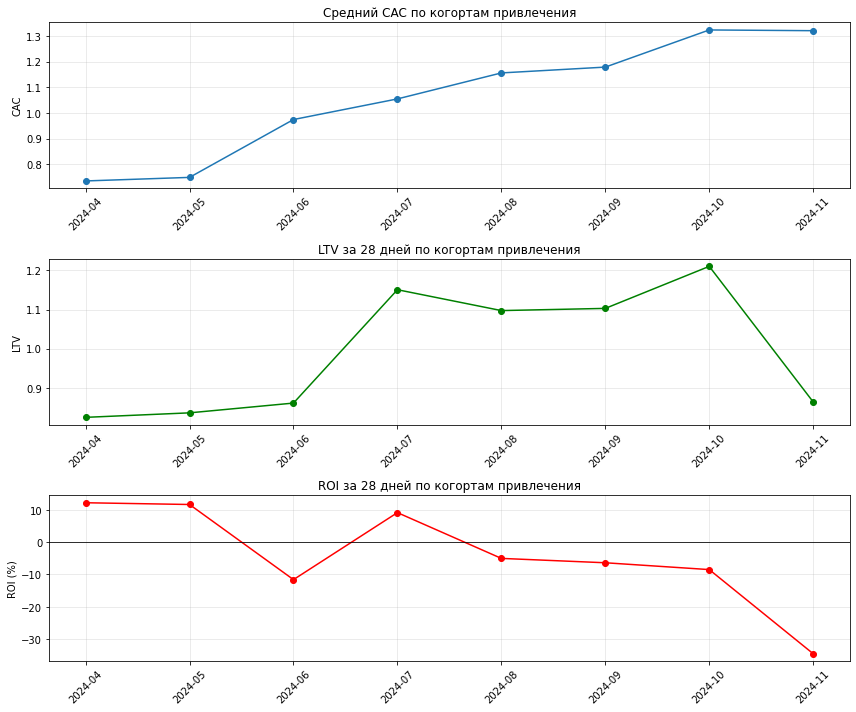

In [15]:
fig, axes = plt.subplots(3, 1, figsize=(12, 10))

axes[0].plot(cohort_metrics['cohort_month'].astype(str), cohort_metrics['avg_cac'], marker='o')
axes[0].set_title('Средний CAC по когортам привлечения')
axes[0].set_ylabel('CAC')
axes[0].grid(True, alpha=0.3)
axes[0].tick_params(axis='x', rotation=45)

axes[1].plot(cohort_metrics['cohort_month'].astype(str), cohort_metrics['ltv_28'], marker='o', color='green')
axes[1].set_title('LTV за 28 дней по когортам привлечения')
axes[1].set_ylabel('LTV')
axes[1].grid(True, alpha=0.3)
axes[1].tick_params(axis='x', rotation=45)

axes[2].plot(cohort_metrics['cohort_month'].astype(str), cohort_metrics['roi_28_pct'], marker='o', color='red')
axes[2].axhline(y=0, color='black', linestyle='-', linewidth=0.8)
axes[2].set_title('ROI за 28 дней по когортам привлечения')
axes[2].set_ylabel('ROI (%)')
axes[2].grid(True, alpha=0.3)
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

### Промежуточный вывод
- DAU и MAU вырос .

- Stickiness остаётся низким (5.7–6.2%), что говорит о нерегулярном использовании приложения.

- CAC начал расти с июня (с 1.05 до 1.3), LTV вырос с примерно 0.85 до 1.15 в июне, а затем упал до примерно 0.85 к ноябрю.

- ROI когорт: апрель-май – положительный (+12%), июнь – отрицательный (-11%), июль – снова положительный (+9%), август-ноябрь – отрицательный (от -5% до -34%).

- Причина стагнации выручки: рост CAC не компенсируется ростом LTV.

## Анализ метрик в разрезе источника привлечения

Теперь необходимо разобраться, какие источники привлечения перспективны, а какие за 28 дней не окупились.

**Задача 1**. Определите самые популярные источники привлечения:
- Посчитайте общее число привлечённых пользователей для каждого источника.
- Визуализируйте динамику набора новых пользователей по дням в каждом источнике.
- Рассчитайте и визуализируйте динамику DAU, MAU и Stickiness по источникам привлечения.

**Задача 2**. Изучите динамику изменения метрик на 28-й день в разрезе источника. Проведите анализ с выделением недельных когорт по дате привлечения. Рассчитайте и визуализируйте:
- Скользящее удержание на 14-й день с момента привлечения (за период с 14-го по 28-й день).
- Конверсию в покупку.

Недельную динамику затрат на маркетинг по каждому источнику привлечения.
Динамику среднего CAC, значений LTV и ROI.

По результатам проведите анализ рекламных каналов. Дайте общую характеристику каждому рекламному каналу по рассчитанным метрикам. Укажите, какие рекламные каналы не вышли на уровень окупаемости за ожидаемый период, и предположите почему.


    first_channel  total_users
0        FaceBoom        28401
3          TipTop        18118
2  RocketSuperAds        14257
1    MediaTornado        14080


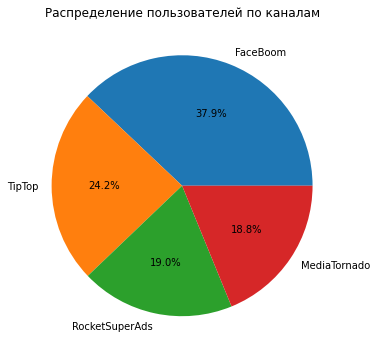

In [16]:
channel_users = profiles.groupby('first_channel')['user_id'].nunique().reset_index(name='total_users')
channel_users = channel_users.sort_values('total_users', ascending=False)
print(channel_users.head())

plt.figure(figsize=(12, 6))
plt.pie(channel_users['total_users'], labels=channel_users['first_channel'], autopct='%1.1f%%')
plt.title('Распределение пользователей по каналам')
plt.show()

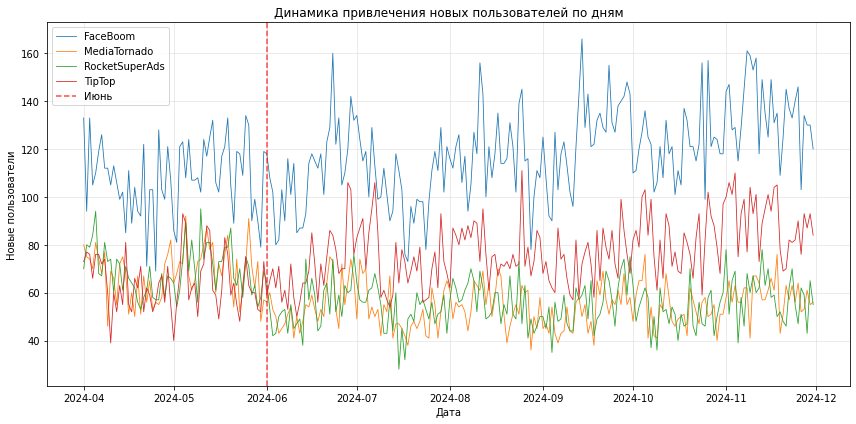

In [17]:
daily_users_by_channel = profiles.groupby([profiles['first_dt'].dt.date, 'first_channel'])['user_id'].nunique().reset_index()
daily_users_by_channel.columns = ['date', 'channel', 'new_users']

plt.figure(figsize=(12, 6))
for channel in daily_users_by_channel['channel'].unique():
    subset = daily_users_by_channel[daily_users_by_channel['channel'] == channel]
    plt.plot(subset['date'], subset['new_users'], label=channel, linewidth=0.8)
plt.axvline(x=pd.Timestamp('2024-06-01').date(), color='red', linestyle='--', alpha=0.7, label='Июнь')
plt.legend()
plt.title('Динамика привлечения новых пользователей по дням')
plt.xlabel('Дата')
plt.ylabel('Новые пользователи')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

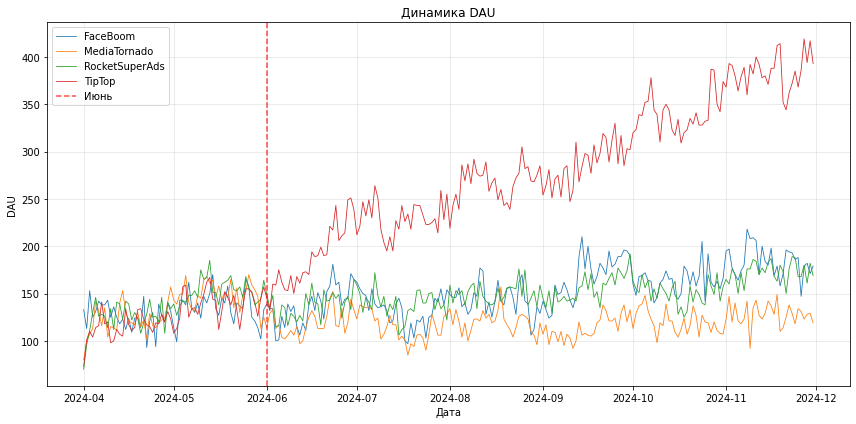

In [18]:
dau_by_channel = visits.groupby([visits['session_start'].dt.date, 'channel'])['user_id'].nunique().reset_index()
dau_by_channel.columns = ['date', 'channel', 'dau']

plt.figure(figsize=(12, 6))
for channel in dau_by_channel['channel'].unique():
    subset = dau_by_channel[dau_by_channel['channel'] == channel]
    plt.plot(subset['date'], subset['dau'], label=channel, linewidth=0.8)

plt.axvline(x=pd.Timestamp('2024-06-01'), color='red', linestyle='--', alpha=0.7, label='Июнь')
plt.legend()
plt.title('Динамика DAU')
plt.xlabel('Дата')
plt.ylabel('DAU')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

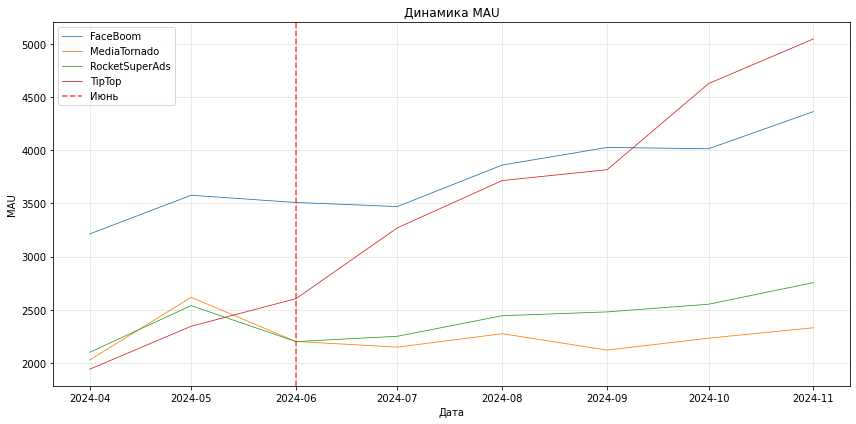

In [19]:
mau_by_channel = visits.groupby([visits['session_start'].dt.to_period('M'), 'channel'])['user_id'].nunique().reset_index()
mau_by_channel.columns = ['month', 'channel', 'mau']
mau_by_channel['month'] = mau_by_channel['month'].dt.to_timestamp()

plt.figure(figsize=(12, 6))
for channel in mau_by_channel['channel'].unique():
    subset = mau_by_channel[mau_by_channel['channel'] == channel]
    plt.plot(subset['month'], subset['mau'], label=channel, linewidth=0.8)

plt.axvline(x=pd.Timestamp('2024-06-01'), color='red', linestyle='--', alpha=0.7, label='Июнь')
plt.legend()
plt.title('Динамика MAU')
plt.xlabel('Дата')
plt.ylabel('MAU')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

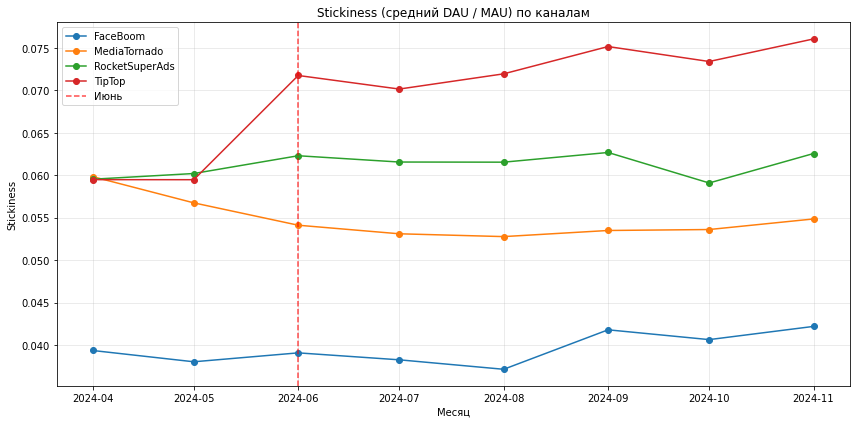

In [20]:
dau_by_channel['date'] = pd.to_datetime(dau_by_channel['date'])
dau_by_channel['month'] = dau_by_channel['date'].dt.to_period('M').dt.to_timestamp()

avg_dau_by_channel_month = dau_by_channel.groupby(['month', 'channel'])['dau'].mean().reset_index()
avg_dau_by_channel_month.columns = ['month', 'channel', 'avg_dau']

stickiness_by_channel = avg_dau_by_channel_month.merge(mau_by_channel, on=['month', 'channel'], how='inner')
stickiness_by_channel['stickiness'] = stickiness_by_channel['avg_dau'] / stickiness_by_channel['mau']

plt.figure(figsize=(12, 6))
for channel in stickiness_by_channel['channel'].unique():
    subset = stickiness_by_channel[stickiness_by_channel['channel'] == channel]
    plt.plot(subset['month'], subset['stickiness'], marker='o', label=channel, linewidth=1.5)

plt.axvline(x=pd.Timestamp('2024-06-01'), color='red', linestyle='--', alpha=0.7, label='Июнь')
plt.legend()
plt.title('Stickiness (средний DAU / MAU) по каналам')
plt.xlabel('Месяц')
plt.ylabel('Stickiness')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [21]:
visits_with_cohort = visits.merge(
    profiles[['user_id', 'first_dt']],
    on='user_id',
    how='left'
)

visits_with_cohort['life_day'] = (visits_with_cohort['session_start'] - visits_with_cohort['first_dt']).dt.days

visits_14_27_days = visits_with_cohort[visits_with_cohort['life_day'].between(14, 27)]

user_retention_14_27_days = visits_14_27_days.groupby('user_id')['life_day'].count().reset_index()
user_retention_14_27_days['retained_14_27_days'] = True

all_users = profiles[['user_id', 'first_dt', 'first_channel']].copy()
user_retention_14_27_days = all_users.merge(user_retention_14_27_days[['user_id', 'retained_14_27_days']], on='user_id', how='left')
user_retention_14_27_days['retained_14_27_days'] = user_retention_14_27_days['retained_14_27_days'].fillna(False)

user_retention_14_27_days['cohort_week'] = user_retention_14_27_days['first_dt'].dt.to_period('W')

retention_by_week_channel = user_retention_14_27_days.groupby(['cohort_week', 'first_channel'])['retained_14_27_days'].mean().reset_index()
retention_by_week_channel.columns = ['cohort_week', 'channel', 'retention_14_27']

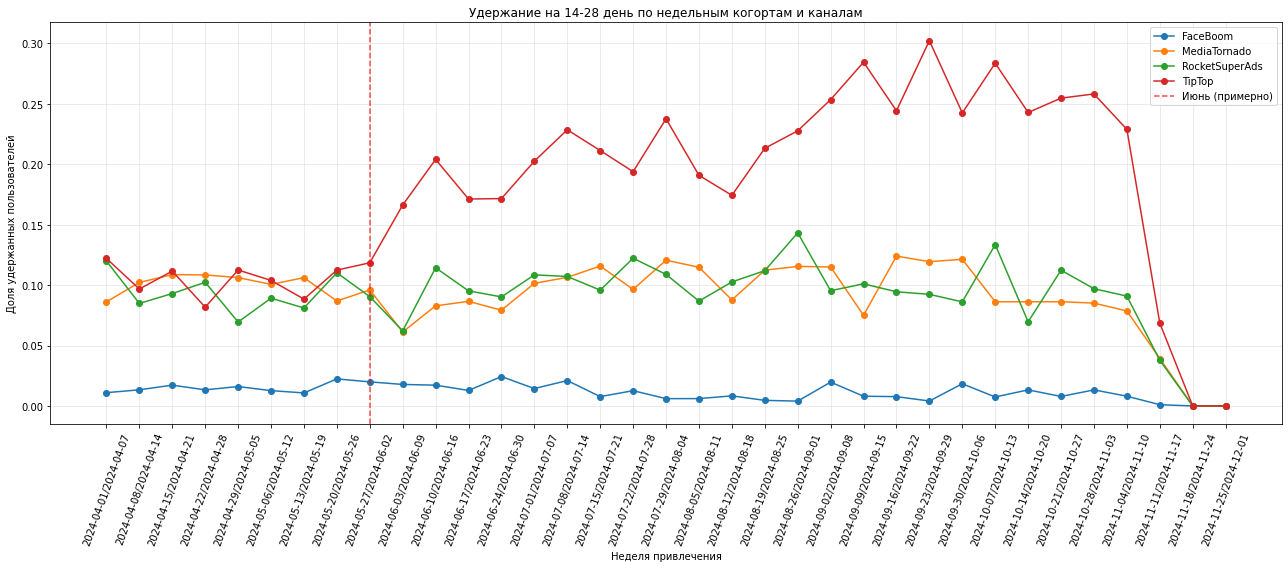

In [22]:
plt.figure(figsize=(18, 8))
for channel in retention_by_week_channel['channel'].unique():
    subset = retention_by_week_channel[retention_by_week_channel['channel'] == channel]
    plt.plot(subset['cohort_week'].astype(str), subset['retention_14_27'], marker='o', label=channel, linewidth=1.5)

plt.axvline(x=8, color='red', linestyle='--', alpha=0.7, label='Июнь (примерно)')  
plt.legend()
plt.title('Удержание на 14-28 день по недельным когортам и каналам')
plt.xlabel('Неделя привлечения')
plt.ylabel('Доля удержанных пользователей')
plt.xticks(rotation=70)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

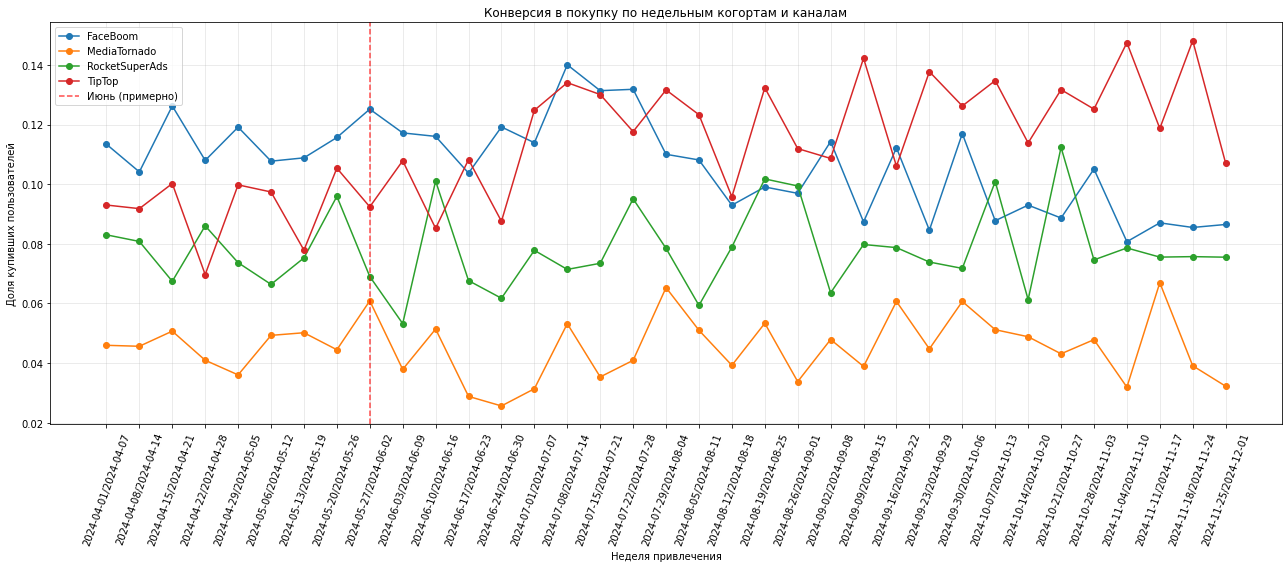

In [23]:
cohort_revenue = cohort_revenue.merge(
    profiles[['user_id', 'first_dt']],
    on='user_id',
    how='left'
)

cohort_revenue_with_channel = cohort_revenue.merge(
    profiles[['user_id', 'first_channel']],
    on='user_id',
    how='left'
)

cohort_revenue_with_channel['cohort_week'] = cohort_revenue_with_channel['first_dt'].dt.to_period('W')

conversion_by_week_channel = cohort_revenue_with_channel.groupby(['cohort_week', 'first_channel']).agg(
    conversion=('revenue', lambda x: (x > 0).mean()),
    users=('user_id', 'count')
).reset_index()

plt.figure(figsize=(18, 8))
for channel in conversion_by_week_channel['first_channel'].unique():
    subset = conversion_by_week_channel[conversion_by_week_channel['first_channel'] == channel]
    plt.plot(subset['cohort_week'].astype(str), subset['conversion'], marker='o', label=channel, linewidth=1.5)

plt.axvline(x=8, color='red', linestyle='--', alpha=0.7, label='Июнь (примерно)')
plt.legend()
plt.title('Конверсия в покупку по недельным когортам и каналам')
plt.xlabel('Неделя привлечения')
plt.ylabel('Доля купивших пользователей')
plt.xticks(rotation=70)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

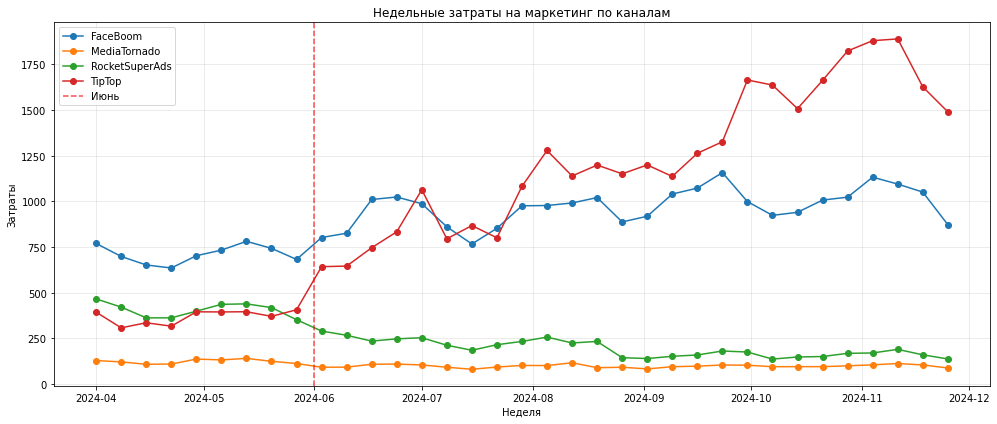

In [24]:
costs['week'] = costs['dt'].dt.to_period('W')

costs_by_week_channel = costs.groupby(['week', 'channel'])['costs'].sum().reset_index()

costs_by_week_channel['week_start'] = costs_by_week_channel['week'].dt.start_time

plt.figure(figsize=(14, 6))
for channel in costs_by_week_channel['channel'].unique():
    subset = costs_by_week_channel[costs_by_week_channel['channel'] == channel]
    plt.plot(subset['week_start'], subset['costs'], marker='o', label=channel, linewidth=1.5)

plt.axvline(x=pd.Timestamp('2024-06-01'), color='red', linestyle='--', alpha=0.7, label='Июнь')
plt.legend()
plt.title('Недельные затраты на маркетинг по каналам')
plt.xlabel('Неделя')
plt.ylabel('Затраты')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [25]:
cohort_revenue_merged = cohort_revenue.merge(
    profiles[['user_id', 'first_channel', 'first_dt']],
    on='user_id',
    how='inner'
)

cohort_revenue_merged['cohort_week'] = profiles['first_dt'].dt.to_period('W')

ltv_by_week_channel = cohort_revenue_merged.groupby(['cohort_week', 'first_channel'])['revenue'].mean().reset_index()
ltv_by_week_channel.columns = ['cohort_week', 'channel', 'ltv_28']

profiles['cohort_week'] = profiles['first_dt'].dt.to_period('W')

cac_by_week_channel = profiles.groupby(['cohort_week', 'first_channel'])['cac'].mean().reset_index()
cac_by_week_channel.columns = ['cohort_week', 'channel', 'avg_cac']

metrics_by_week_channel = ltv_by_week_channel.merge(cac_by_week_channel, on=['cohort_week', 'channel'], how='inner')
metrics_by_week_channel['roi_28'] = (metrics_by_week_channel['ltv_28'] - metrics_by_week_channel['avg_cac']) / metrics_by_week_channel['avg_cac']
metrics_by_week_channel['roi_28_pct'] = metrics_by_week_channel['roi_28'] * 100

metrics_by_week_channel['week_start'] = metrics_by_week_channel['cohort_week'].dt.start_time
ltv_by_week_channel['week_start'] = ltv_by_week_channel['cohort_week'].dt.start_time
cac_by_week_channel['week_start'] = cac_by_week_channel['cohort_week'].dt.start_time

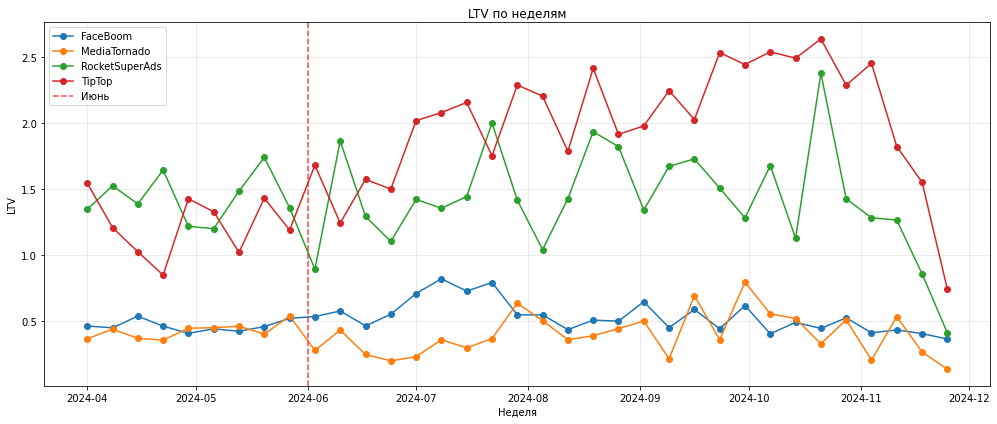

In [26]:
plt.figure(figsize=(14, 6))
for channel in ltv_by_week_channel['channel'].unique():
    subset = ltv_by_week_channel[ltv_by_week_channel['channel'] == channel]
    plt.plot(subset['week_start'], subset['ltv_28'], marker='o', label=channel, linewidth=1.5)

plt.axvline(x=pd.Timestamp('2024-06-01'), color='red', linestyle='--', alpha=0.7, label='Июнь')
plt.legend()
plt.title('LTV по неделям')
plt.xlabel('Неделя')
plt.ylabel('LTV')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

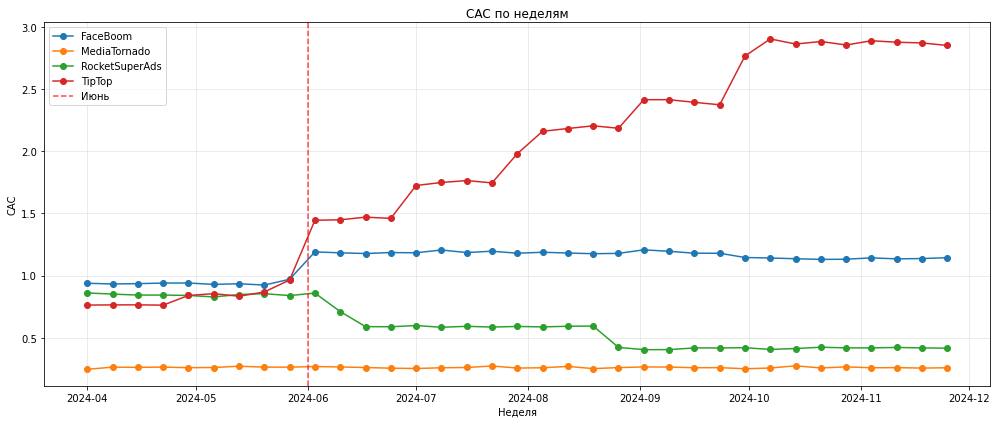

In [27]:
plt.figure(figsize=(14, 6))
for channel in cac_by_week_channel['channel'].unique():
    subset = cac_by_week_channel[cac_by_week_channel['channel'] == channel]
    plt.plot(subset['week_start'], subset['avg_cac'], marker='o', label=channel, linewidth=1.5)

plt.axvline(x=pd.Timestamp('2024-06-01'), color='red', linestyle='--', alpha=0.7, label='Июнь')
plt.legend()
plt.title('CAC по неделям')
plt.xlabel('Неделя')
plt.ylabel('CAC')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

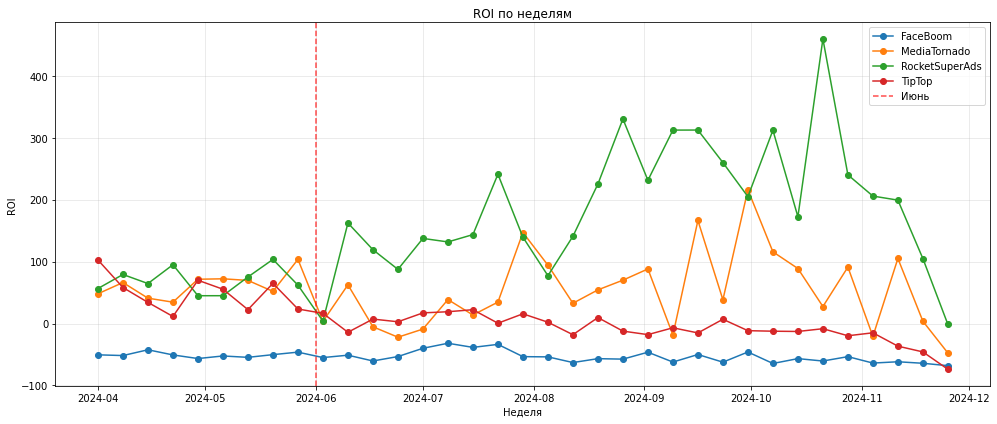

In [28]:
plt.figure(figsize=(14, 6))
for channel in metrics_by_week_channel['channel'].unique():
    subset = metrics_by_week_channel[metrics_by_week_channel['channel'] == channel]
    plt.plot(subset['week_start'], subset['roi_28_pct'], marker='o', label=channel, linewidth=1.5)

plt.axvline(x=pd.Timestamp('2024-06-01'), color='red', linestyle='--', alpha=0.7, label='Июнь')
plt.legend()
plt.title('ROI по неделям')
plt.xlabel('Неделя')
plt.ylabel('ROI')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Промежуточный вывод
- FaceBoom – 38% пользователей, ROI отрицательный на всех неделях (от -31% до -68%) в связи с тем что с юиня вырос CAC (от 0.9 до 1.2) при этом LTV в среднем остался на том же уровне (0.5). Удержание канала остается стабильно низим а так же снижается конверсия. Канал является убыточным, на промежутке к 28 дню не выходит на уровень окупаемости. Требует дополнительного рассмотрения окупаемости за больший период. 

- TipTop – 24% пользователей, ROI положительный в апреле-августе, с сентября отрицательный (до -74% в ноябре). CAC канала постоянно увеличивается (от 0.7 до 2.8) при этом LTV рос вместе с увеличивающимся CAC что обеспечивает минимальную окупаемость до сентября где канал уже перестает окупаться. Канал проблемный требуется дополнительно рассмотреть окупаемость за больший период.

- MediaTornado – CAC самый низкий (0.25), ROI в основном положительный. Конверсия как и удержание колеблятся но остаются на примерно одном и том же уровне. Канал прибыльный однако окупаемость обеспечивается за счет крайне низкого CAC.

- RocketSuperAds – стабильно положительный ROI (от +56% до +459%). CAC канала постепенно снижается, а LTV постепенно растет. Конверсия как и удержание колеблятся но остаются на примерно одном и том же уровне. Канал прибыльный и стабильный.

## Анализ периода окупаемости маркетинговых вложений

Для источников, которые к 28-му дню не выходят на уровень окупаемости, рассчитайте и визуализируйте в виде тепловой карты значения ROI за больший период, например за 8–10 недель.

Разделите данные на недельные когорты по дате привлечения, в качестве интервала наблюдений используйте недели.

Сделайте вывод о том, за какой период окупаются вложения в эти источники.

In [29]:
problem_channels = ['FaceBoom', 'TipTop']

problem_orders = orders_with_cohort.merge(
    profiles[['user_id', 'cohort_week', 'first_channel']],
    on='user_id',
    how='inner'
)
problem_orders = problem_orders[problem_orders['life_day'] <= 70]
problem_orders['week_life'] = problem_orders['life_day'] // 7
problem_orders = problem_orders[problem_orders['first_channel'].isin(problem_channels)]
problem_orders = problem_orders[problem_orders['week_life'] <= 9]

weekly_revenue = problem_orders.groupby(['user_id', 'week_life'])['revenue'].sum().reset_index()

all_users = profiles[profiles['first_channel'].isin(problem_channels)][['user_id', 'first_channel', 'cohort_week']].copy()

all_combinations = all_users.merge(
    pd.DataFrame({'week_life': range(10)}),
    how='cross'
)

all_weekly = all_combinations.merge(
    weekly_revenue[['user_id', 'week_life', 'revenue']],
    on=['user_id', 'week_life'],
    how='left'
)

all_weekly['revenue'] = all_weekly['revenue'].fillna(0)

all_weekly = all_weekly.sort_values(['user_id', 'week_life'])
all_weekly['cumulative_revenue'] = all_weekly.groupby('user_id')['revenue'].cumsum()

ltv_by_week = all_weekly.groupby(['cohort_week', 'first_channel', 'week_life'])['cumulative_revenue'].mean().reset_index()
ltv_by_week.columns = ['cohort_week', 'channel', 'week_life', 'ltv']

cac_by_week = profiles.groupby(['cohort_week', 'first_channel'])['cac'].mean().reset_index()
cac_by_week.columns = ['cohort_week', 'channel', 'avg_cac']

roi_by_week = ltv_by_week.merge(cac_by_week, on=['cohort_week', 'channel'], how='inner')
roi_by_week['roi_pct'] = ((roi_by_week['ltv'] - roi_by_week['avg_cac']) / roi_by_week['avg_cac']) * 100

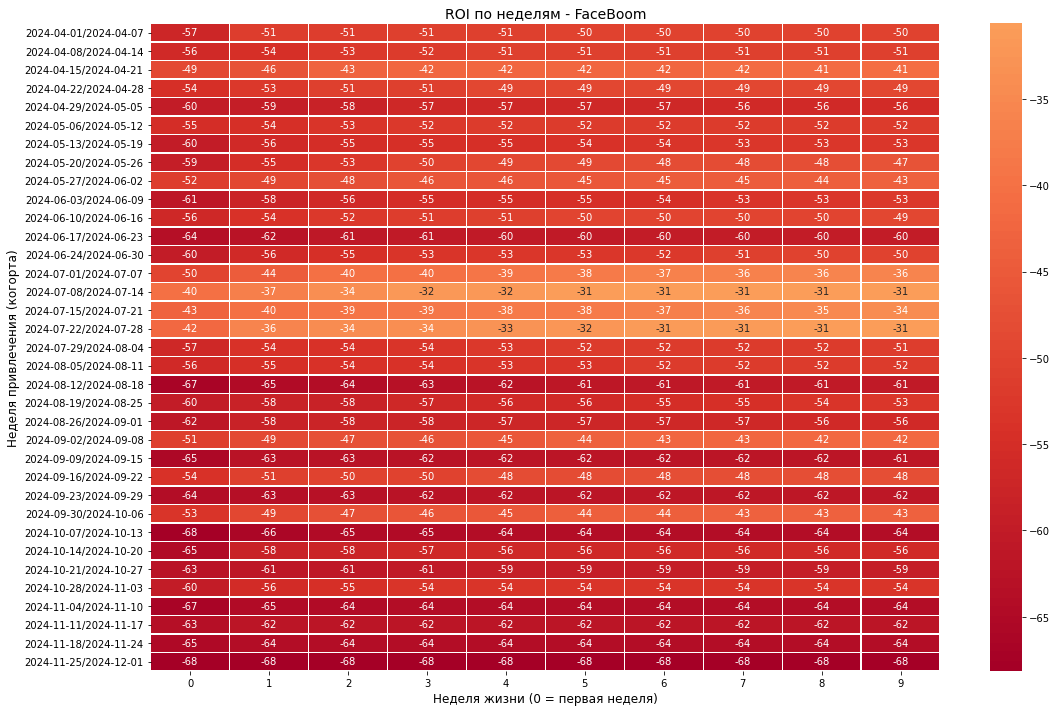

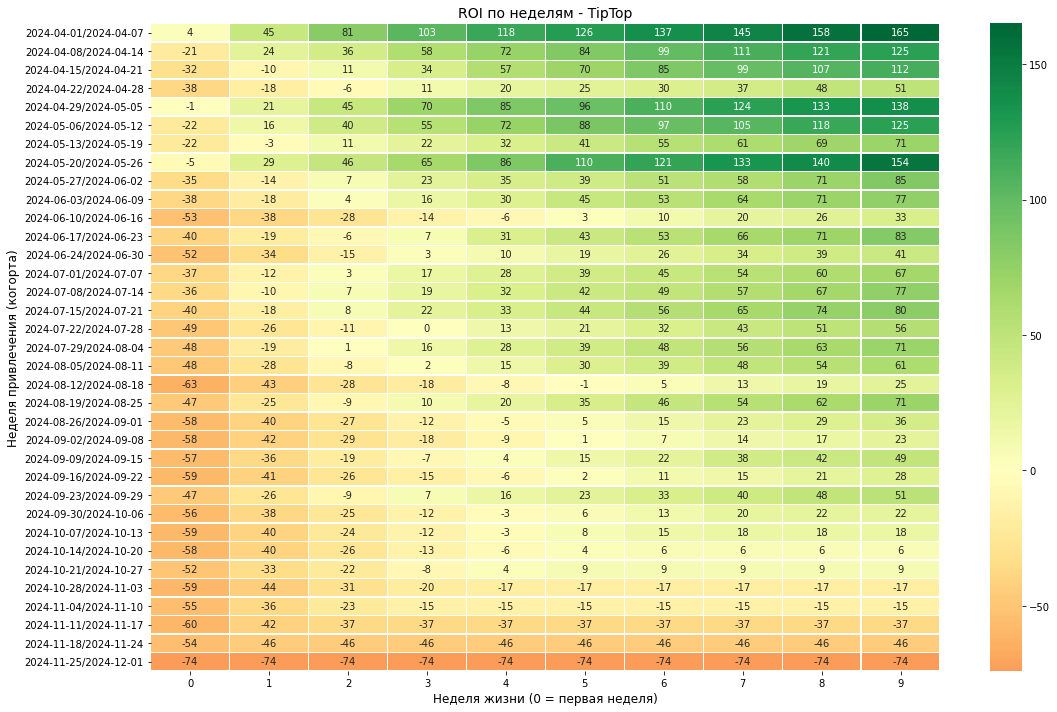

In [30]:
for channel in problem_channels:
    channel_data = roi_by_week[roi_by_week['channel'] == channel].pivot_table(
        index='cohort_week', 
        columns='week_life', 
        values='roi_pct'
    )
    
    plt.figure(figsize=(16, 10))
    sns.heatmap(channel_data, annot=True, fmt='.0f', cmap='RdYlGn', center=0, linewidths=0.5)
    plt.title(f'ROI по неделям - {channel}', fontsize=14)
    plt.xlabel('Неделя жизни (0 = первая неделя)', fontsize=12)
    plt.ylabel('Неделя привлечения (когорта)', fontsize=12)
    plt.tight_layout()
    plt.show()

### Промежуточный вывод
- FaceBoom – не окупается даже за 10 недель (ROI отрицательный на всех неделях).

- TipTop – окупался за 2-4 недели в апреле-августе, с ноября не окупается.

## Выводы и рекомендации

Сформулируйте общий вывод. Зафиксируйте основные результаты и инсайты. Например, охарактеризуйте аудиторию продукта, покажите распределение маркетинговых затрат по каналам привлечения, опишите каждый канал привлечения. Делайте акцент на сильных и слабых сторонах. Укажите, какие каналы привлечения не вышли на окупаемость и по каким причинам.

Дайте рекомендации отделу маркетинга: опишите, как повысить эффективность вложений в рекламу.


### Выводы и рекомендации
1. Общая динамика
    - DAU и MAU выросли после запуска спортивного контента (июнь 2024), но Stickiness остался низким (5.7–6.2%).

    - Выручка стагнирует из-за роста CAC при незначительном увеличении LTV.


2. Проблемные каналы
    - FaceBoom – стабильно убыточный (ROI от –40% до –68%). Удержание канала минимальное среди всех, а так же упала конверсия.

    - TipTop – перестал окупаться с ноября 2024. В остальные месяцы канал окупается однако в связи с постоянно растущим CAC период окупаемости возрастает.


3. Эффективные каналы
    - MediaTornado – сверхдешёвый CAC (0.25), высокий ROI.

    - RocketSuperAds – стабильно окупается.


4. Рекомендации маркетингу
    - FaceBoom – проввести анализ причин низкого удержания и снижения конверсии, потенциально сократить илт отказаться от инвестиций в канал.

    - TipTop – временно приостановить, проверить качество трафика, а именно при высокой конверсии и удержании LTV канала растет не достаточно для покрытия постоянно растущего CAC в рамках бизнес-модели окупаемости пользователя в рамках 28 дней. НО на более длительной дистанции канал окупается.

    - MediaTornado и RocketSuperAds – увеличить бюджеты.

    - Перераспределить средства с неэффективных каналов на эффективные.